In [ ]:
# ==========================================
# STEP 1: IMPORT LIBRARIES
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Train-test splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Plot settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset_C_testing.csv to dataset_C_testing (2).csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset_C_training.csv to dataset_C_training (2).csv


In [ ]:
# ==========================================
# STEP 2: LOAD DATASETS
# ==========================================

train = pd.read_csv("dataset_C_training.csv")
test = pd.read_csv("dataset_C_testing.csv")

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

display(train.head())
display(test.head())

Training dataset shape: (4756, 31)
Testing dataset shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",0.0,0.0,0,4,2,2.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,"MSA, Not Principle City",0.0,0.0,0,2,3,2.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",1.0,0.0,0,3,2,2.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Employed,Non-MSA,1.0,0.0,0,4,4,1.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Employed,Non-MSA,0.0,0.0,0,3,2,1.0,wholesale,0


In [ ]:
# ==========================================
# STEP 3: INITIAL DATA INSPECTION
# ==========================================

# Dataset information
train.info()

# Statistical summary
display(train.describe(include="all").T)

# Column names
print("\nColumn names:")
print(train.columns.tolist())

# Check target variable
print("\nTarget distribution:")
print(train["covid_vaccine"].value_counts())

# Check target percentages
print("\nTarget percentages:")
print(train["covid_vaccine"].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance               2848 non-null   f

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0



Column names:
['respondent_id', 'covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'employment_sector', 'number_chronic_med_conditions', 'covid_vaccine']

Target distribution:
covid_vaccine
0    3202
1    1554
Name: count, dtype: int64

Target percentages:
covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


In [ ]:
# ==========================================
# STEP 4: DATA QUALITY CHECKS
# ==========================================

# Missing values
missing = pd.DataFrame({
    "Missing_Count": train.isnull().sum(),
    "Missing_Percentage": train.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing)

# Duplicate rows
print("Duplicate training rows:", train.duplicated().sum())

# Duplicate respondent IDs
print("Duplicate training IDs:", train["respondent_id"].duplicated().sum())

# Duplicate testing IDs
print("Duplicate testing IDs:", test["respondent_id"].duplicated().sum())

# Check whether IDs overlap
print(
    "Overlapping respondent IDs:",
    train["respondent_id"].isin(test["respondent_id"]).sum()
)

# Check target values
print("Target values:", train["covid_vaccine"].unique())

,Missing_Count,Missing_Percentage
employment_sector,2330,48.990749
health_insurance,1908,40.117746
income_poverty,748,15.727502
rent_or_own,329,6.917578
employment_status,238,5.004205
marital_status,231,4.857023
education,228,4.793944
child_under_6_months,135,2.838520
health_worker,132,2.775442
opinion_covid_sick_from_vacc,90,1.892347


Duplicate training rows: 0
Duplicate training IDs: 0
Duplicate testing IDs: 0
Overlapping respondent IDs: 0
Target values: [0 1]


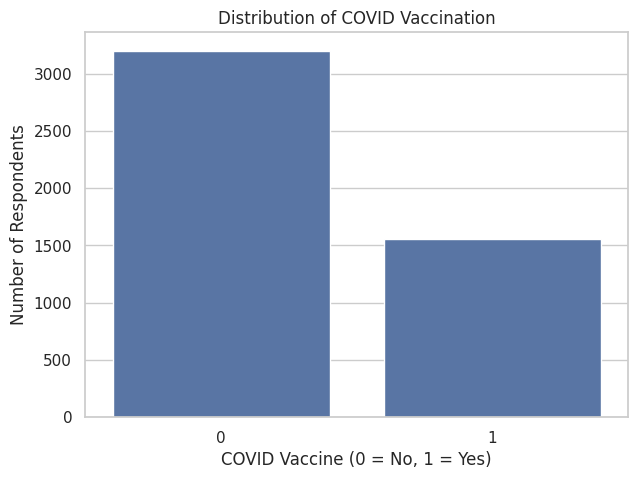

In [ ]:
# ==========================================
# STEP 5: TARGET DISTRIBUTION
# ==========================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x="covid_vaccine"
)

plt.title("Distribution of COVID Vaccination")
plt.xlabel("COVID Vaccine (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")

plt.show()

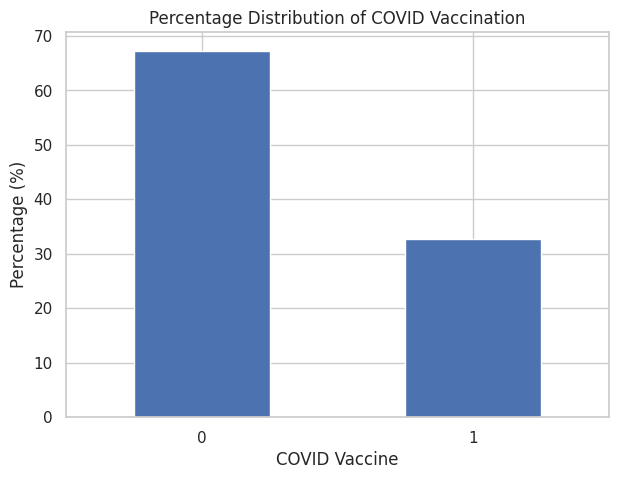

In [ ]:
target_percent = (
    train["covid_vaccine"]
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 5))

target_percent.plot(
    kind="bar",
    rot=0
)

plt.title("Percentage Distribution of COVID Vaccination")
plt.xlabel("COVID Vaccine")
plt.ylabel("Percentage (%)")

plt.show()

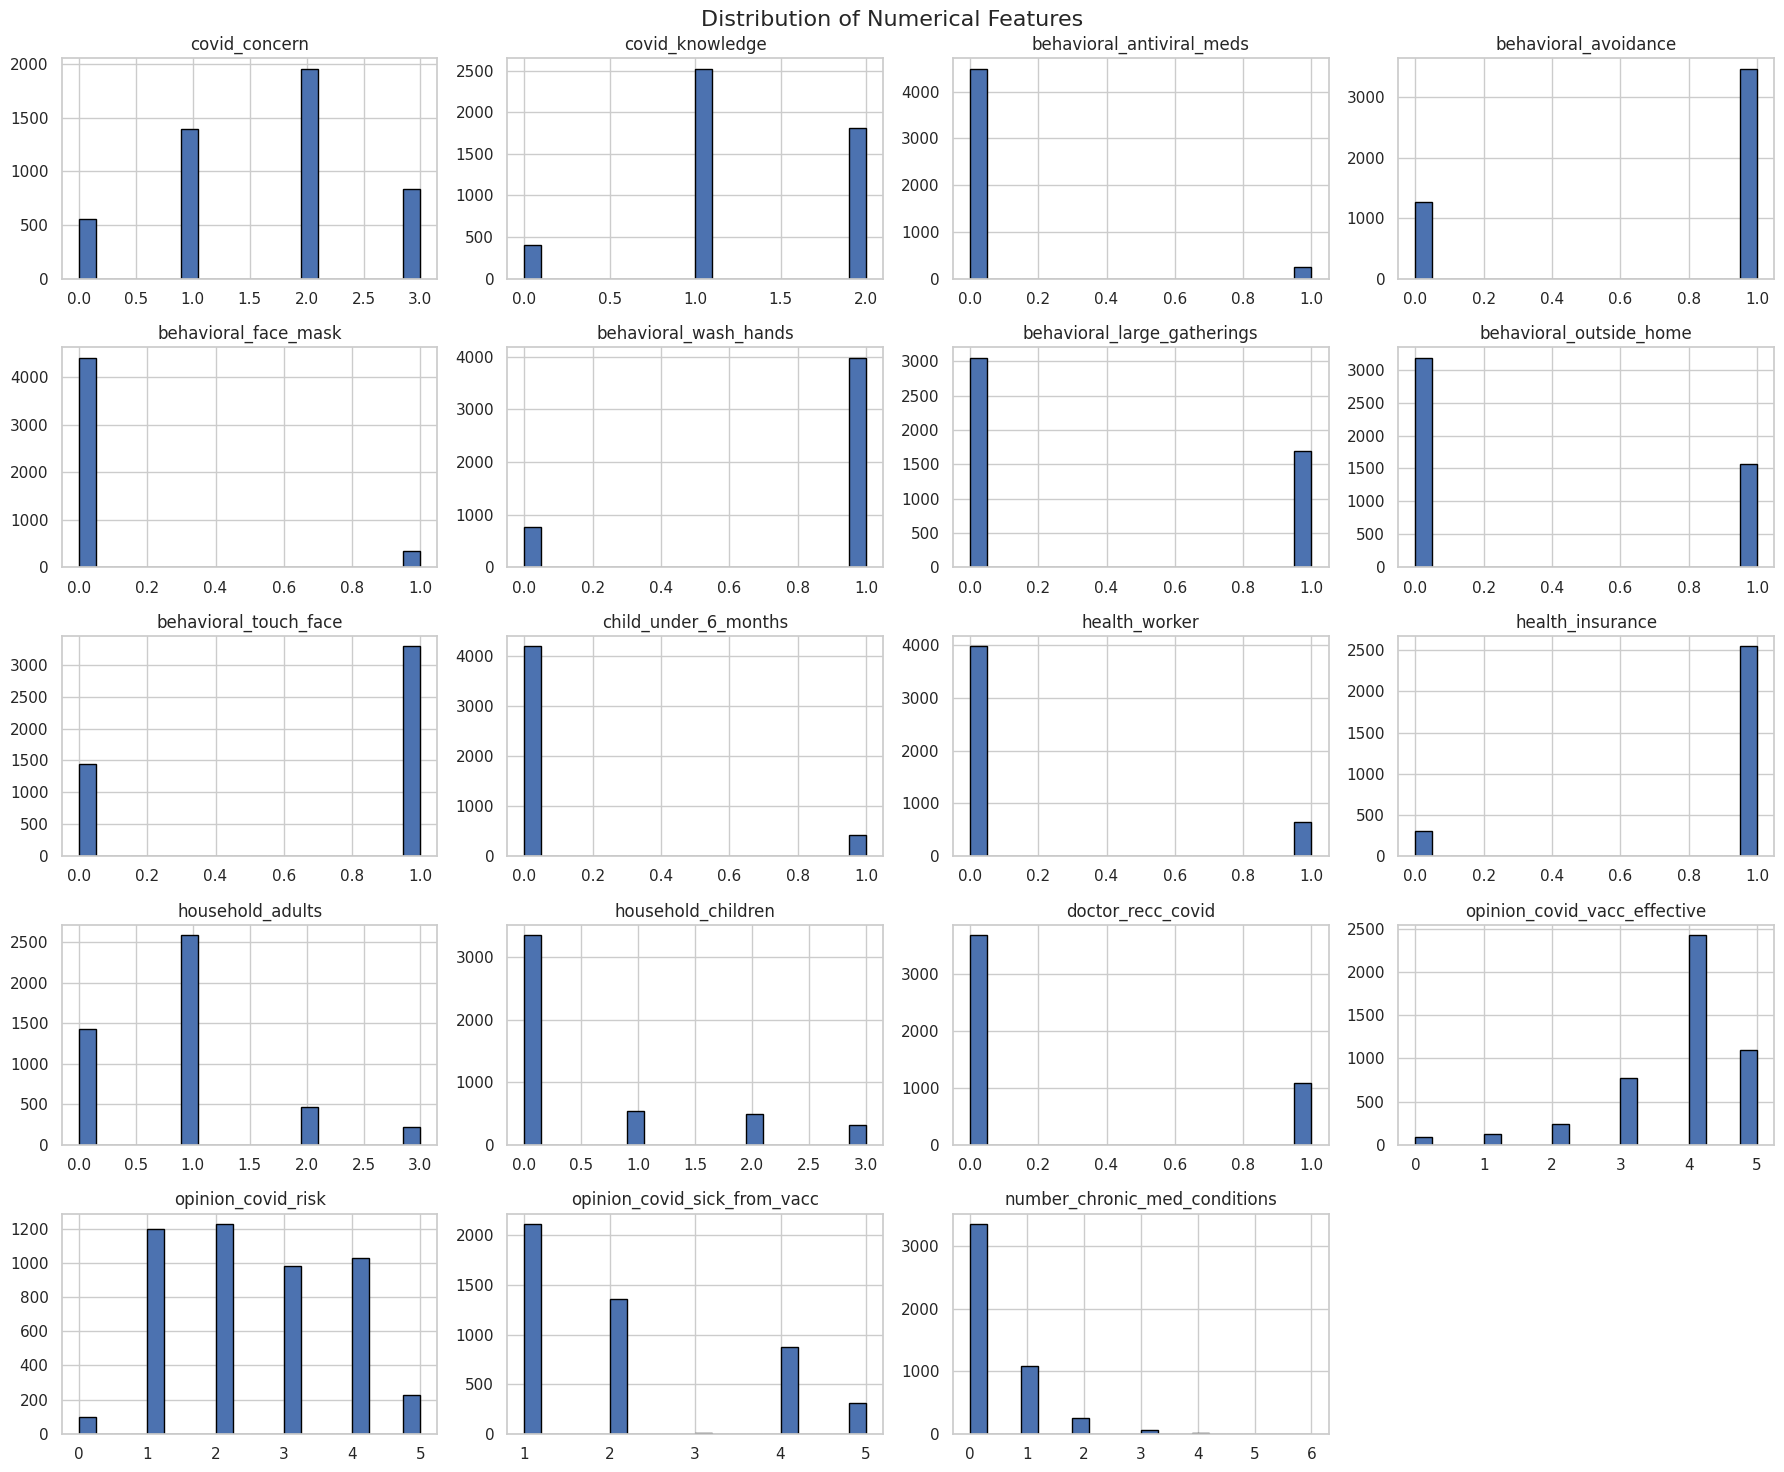

In [ ]:
# ==========================================
# STEP 6: NUMERICAL FEATURE DISTRIBUTIONS
# ==========================================

numeric_features = train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Remove identifier and target
numeric_features = [
    col for col in numeric_features
    if col not in ["respondent_id", "covid_vaccine"]
]

train[numeric_features].hist(
    figsize=(18, 15),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

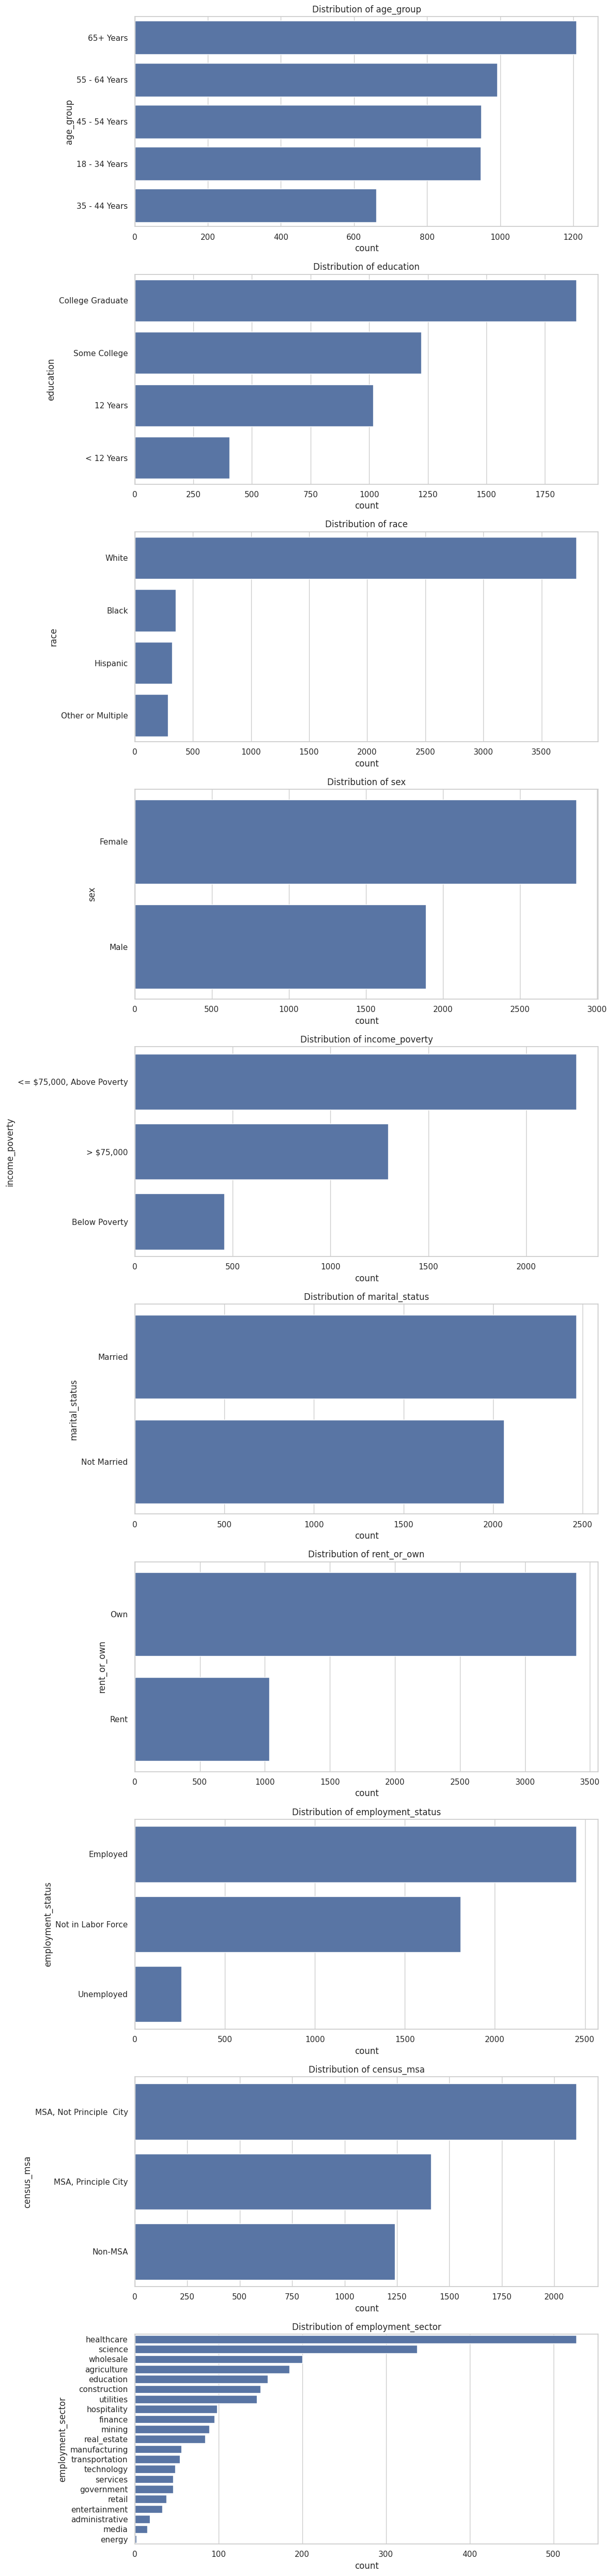

In [ ]:
# ==========================================
# STEP 7: CATEGORICAL FEATURE DISTRIBUTIONS
# ==========================================

categorical_features = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

fig, axes = plt.subplots(
    nrows=len(categorical_features),
    ncols=1,
    figsize=(12, 5 * len(categorical_features))
)

if len(categorical_features) == 1:
    axes = [axes]

for feature, ax in zip(categorical_features, axes):

    order = train[feature].value_counts().index

    sns.countplot(
        data=train,
        y=feature,
        order=order,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

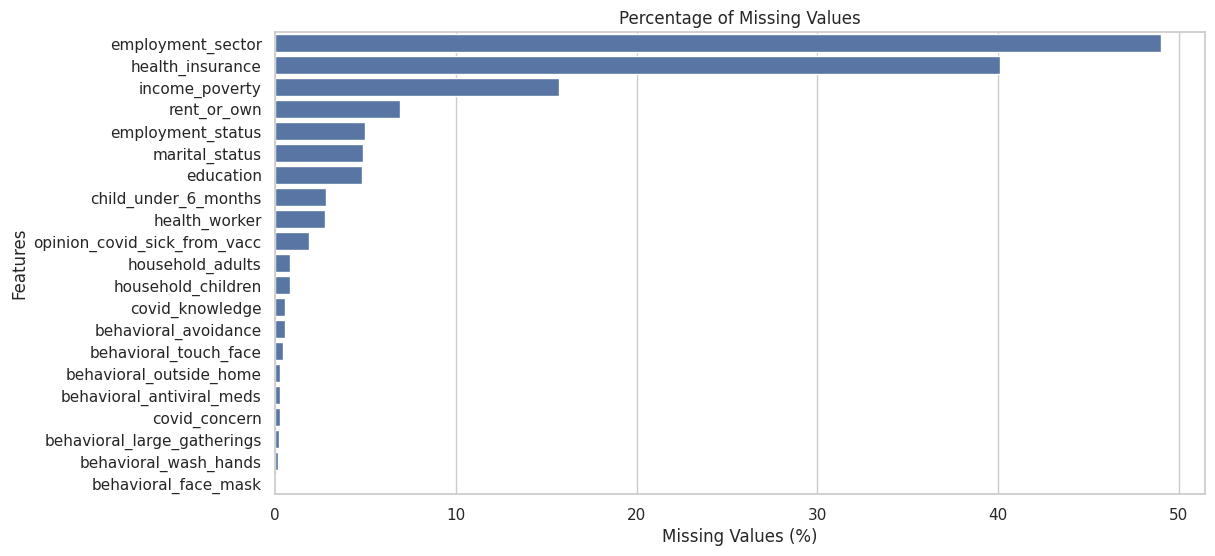

In [ ]:
missing_percent = (
    train.isnull().mean() * 100
).sort_values(ascending=False)

missing_percent = missing_percent[
    missing_percent > 0
]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Percentage of Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")

plt.show()

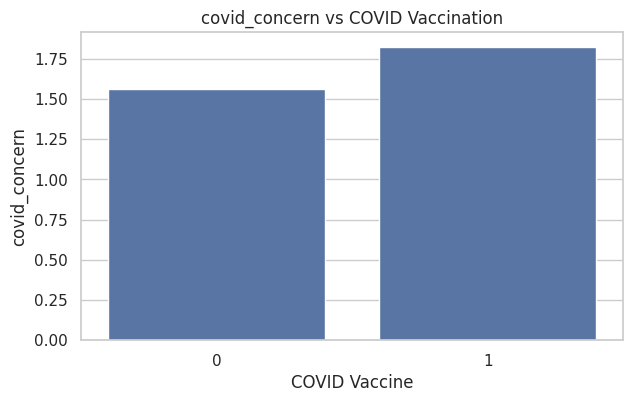

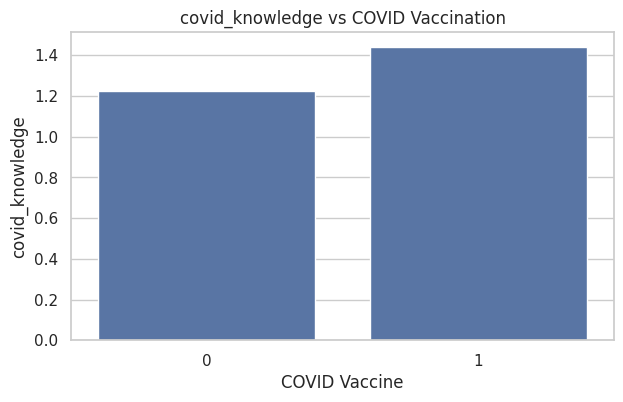

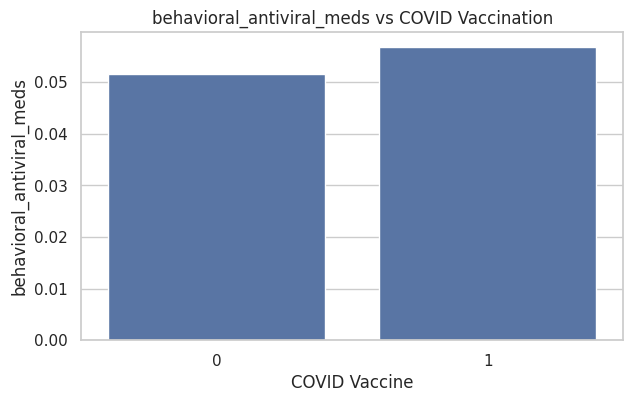

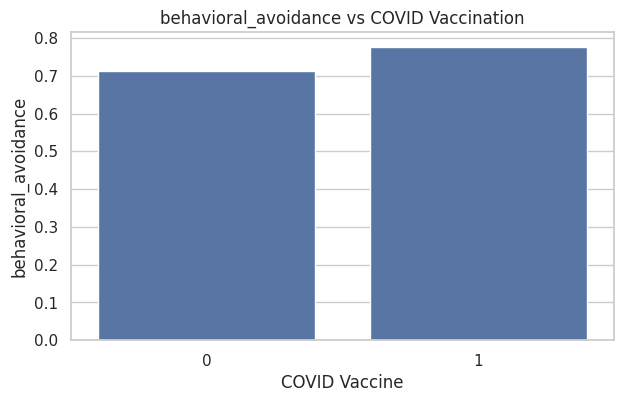

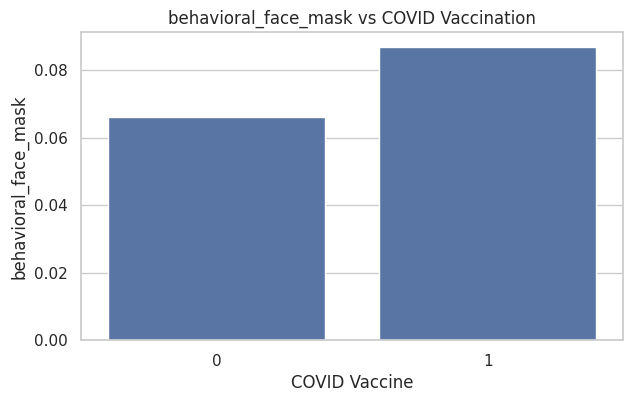

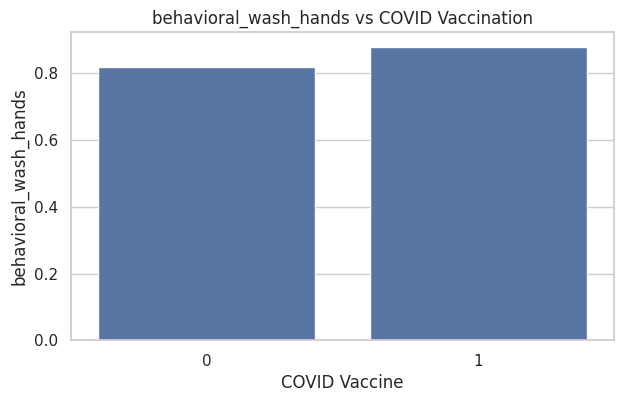

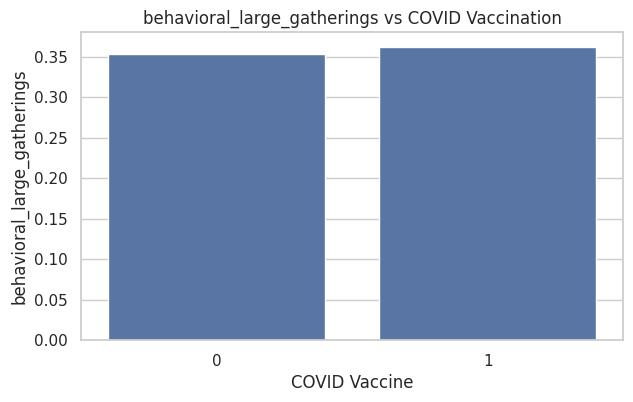

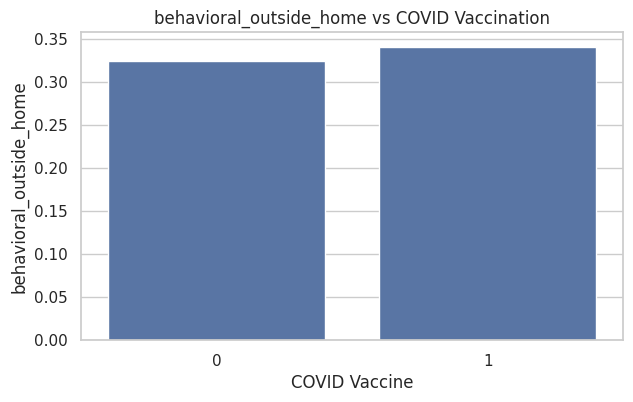

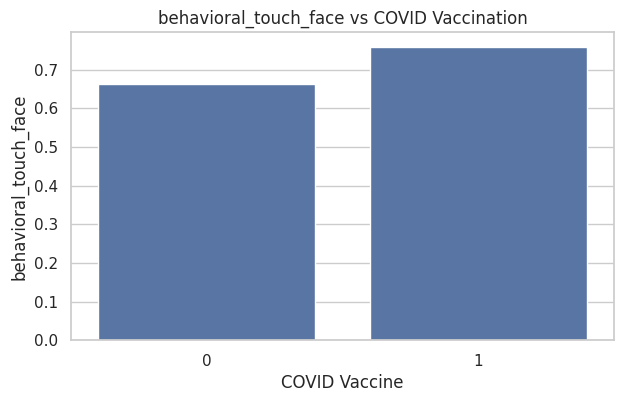

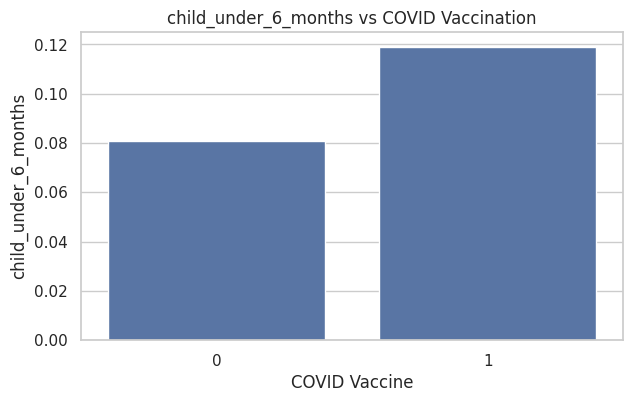

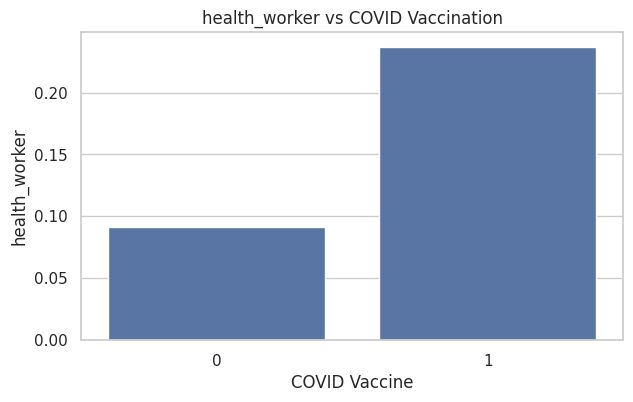

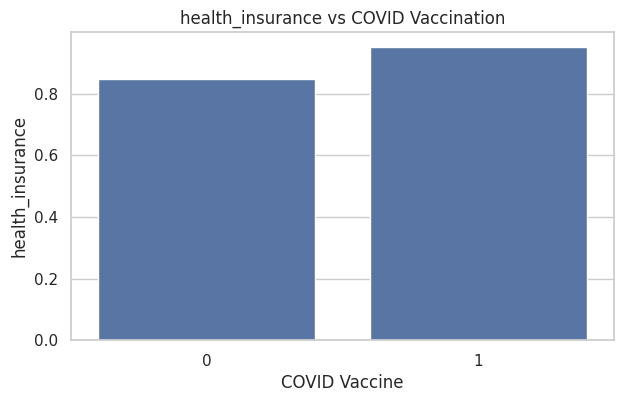

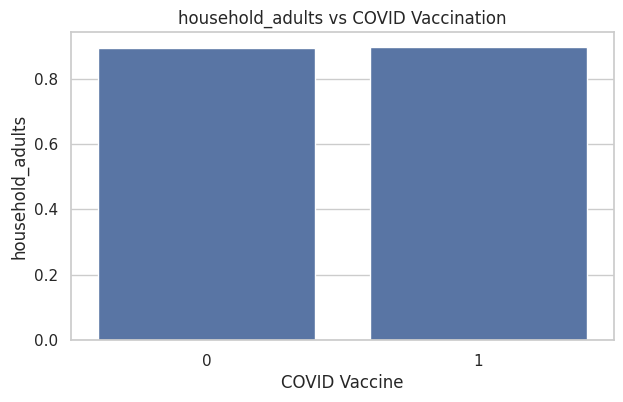

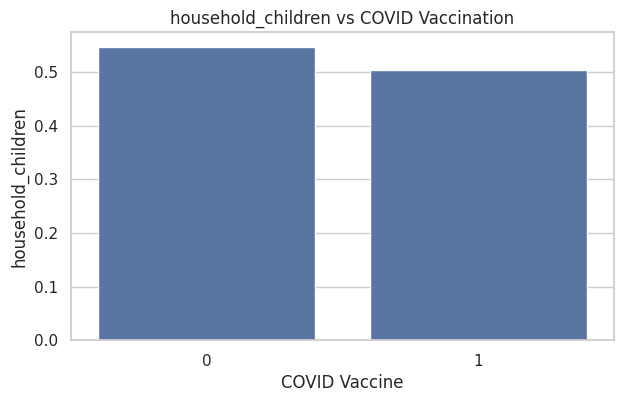

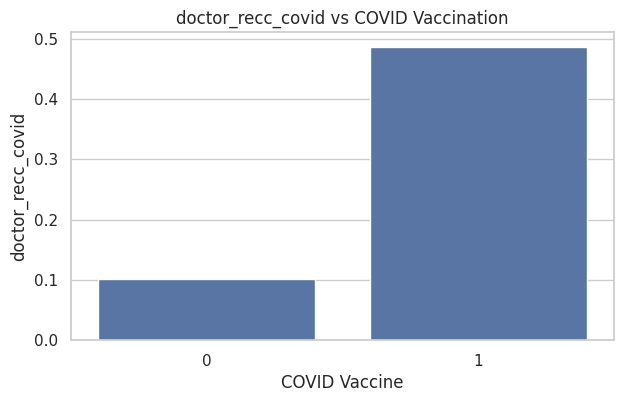

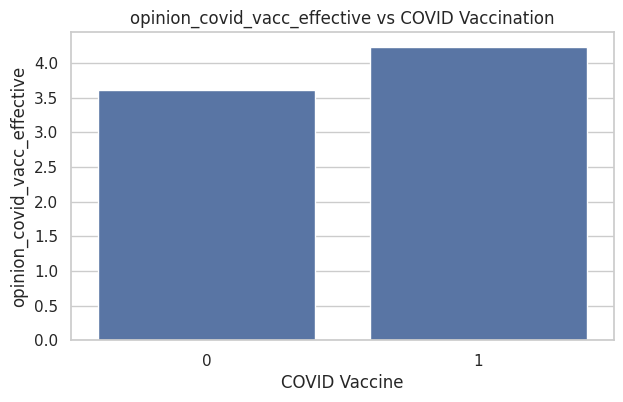

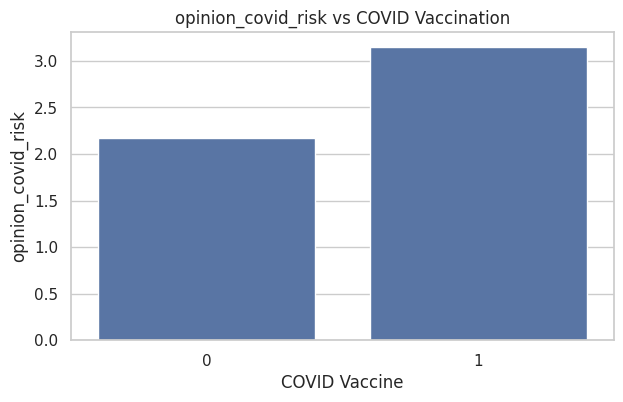

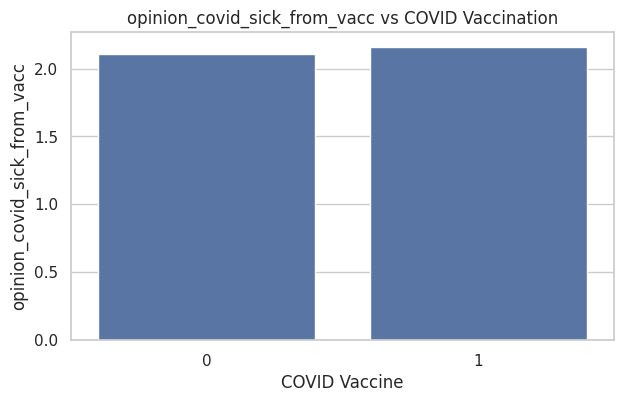

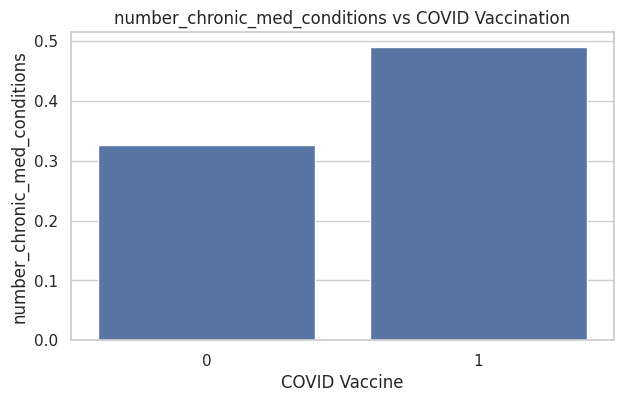

In [ ]:
# ==========================================
# STEP 9A: NUMERICAL FEATURES VS TARGET
# ==========================================

for feature in numeric_features:

    plt.figure(figsize=(7, 4))

    sns.barplot(
        data=train,
        x="covid_vaccine",
        y=feature,
        errorbar=None
    )

    plt.title(f"{feature} vs COVID Vaccination")
    plt.xlabel("COVID Vaccine")
    plt.ylabel(feature)

    plt.show()

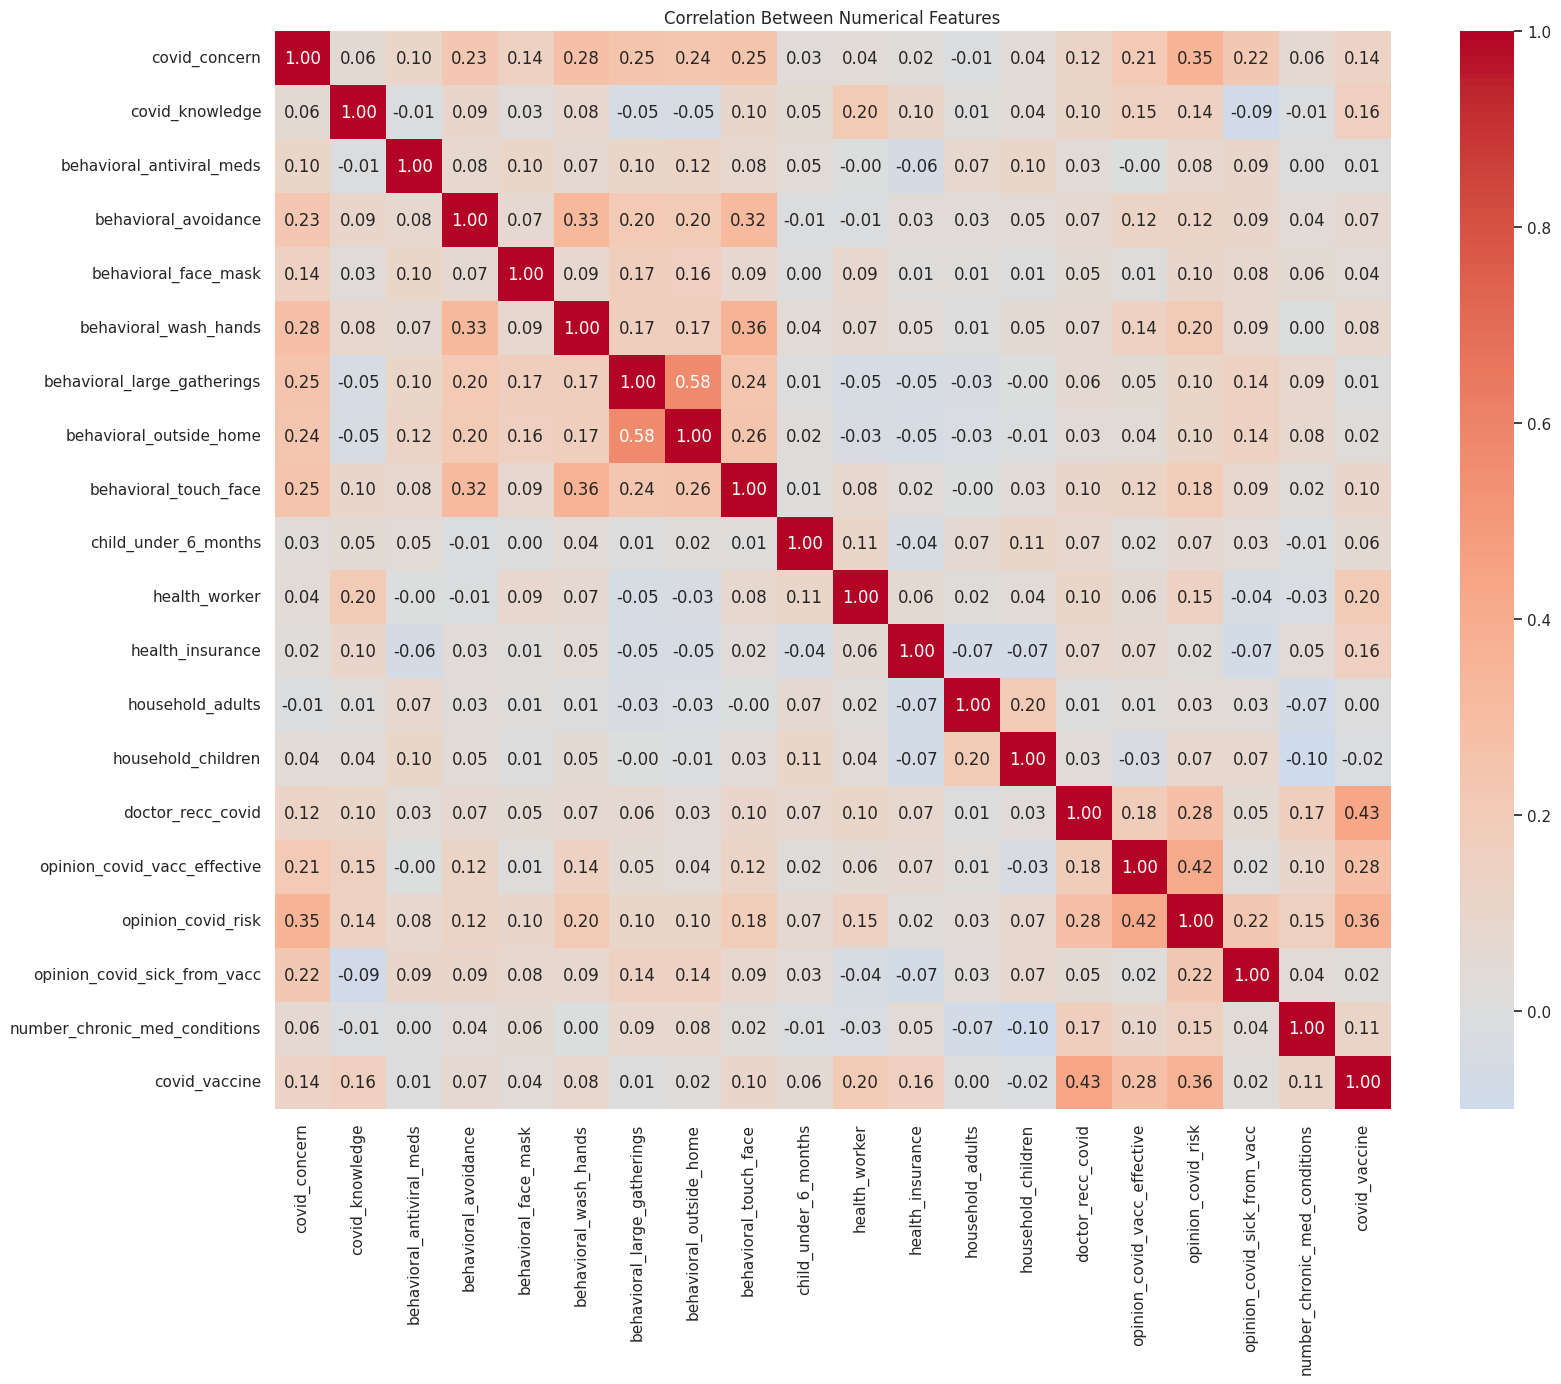

In [ ]:
# ==========================================
# STEP 10: CORRELATION HEATMAP
# ==========================================

correlation = train[numeric_features + ["covid_vaccine"]].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Numerical Features")

plt.show()

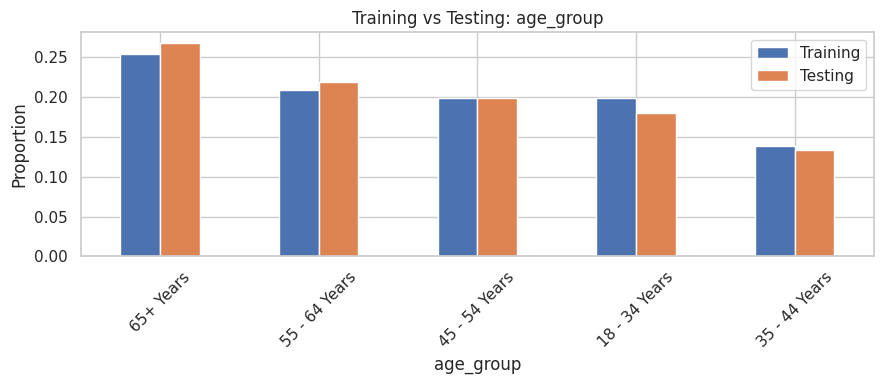

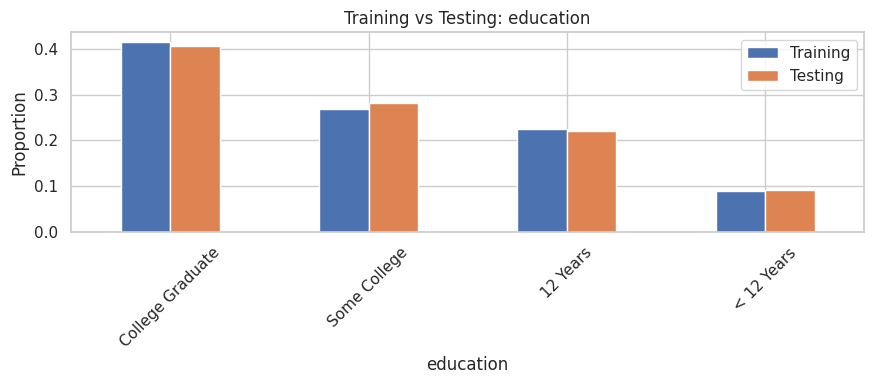

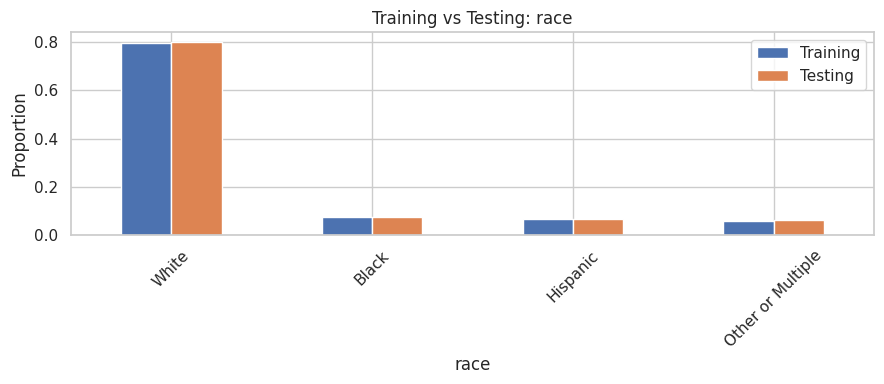

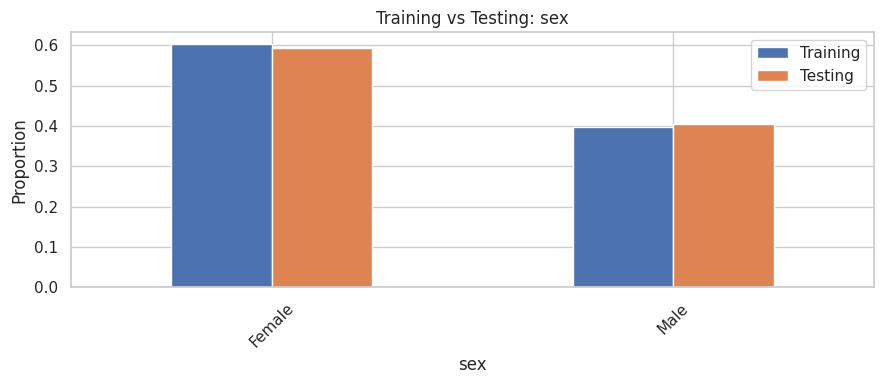

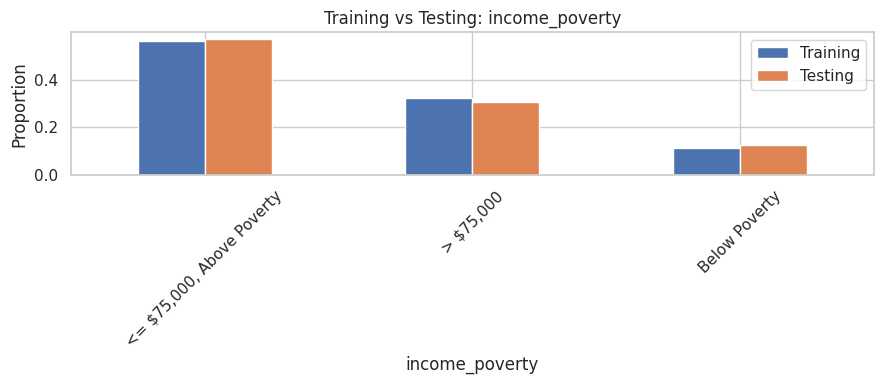

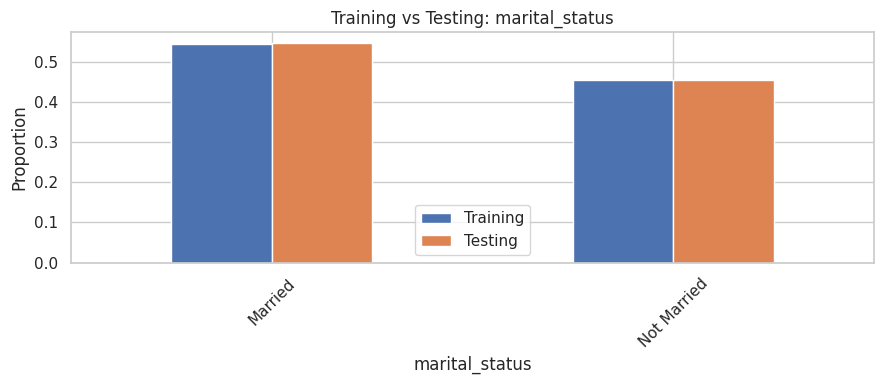

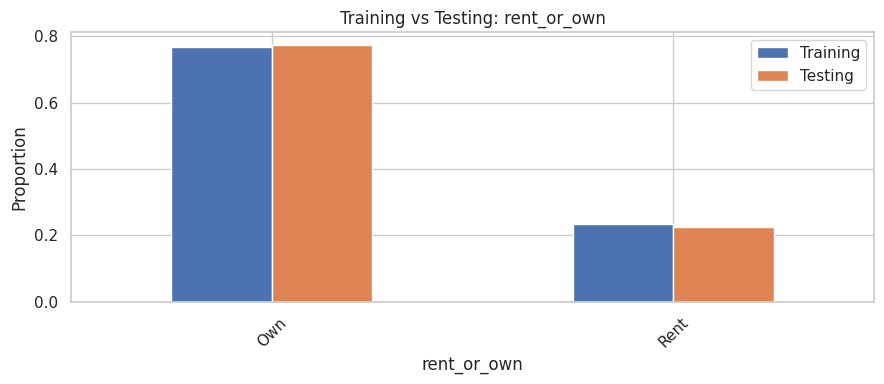

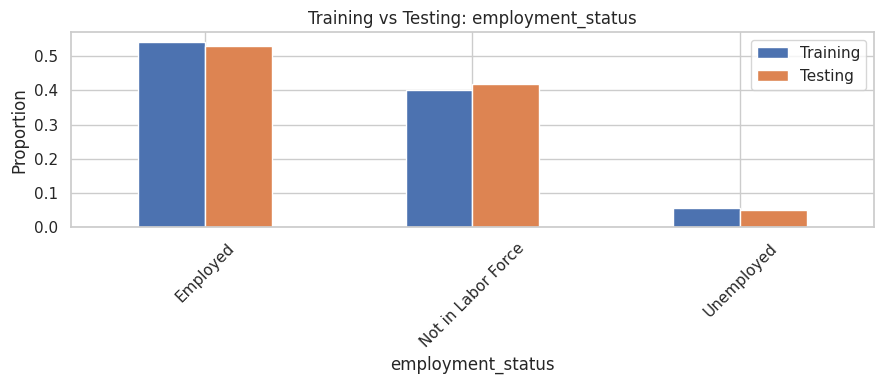

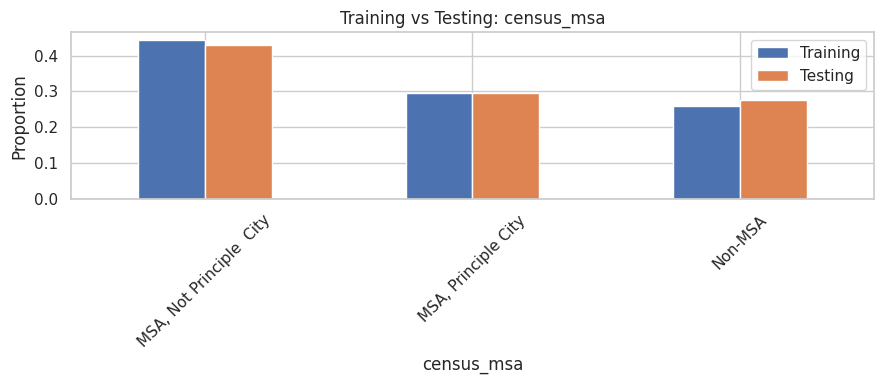

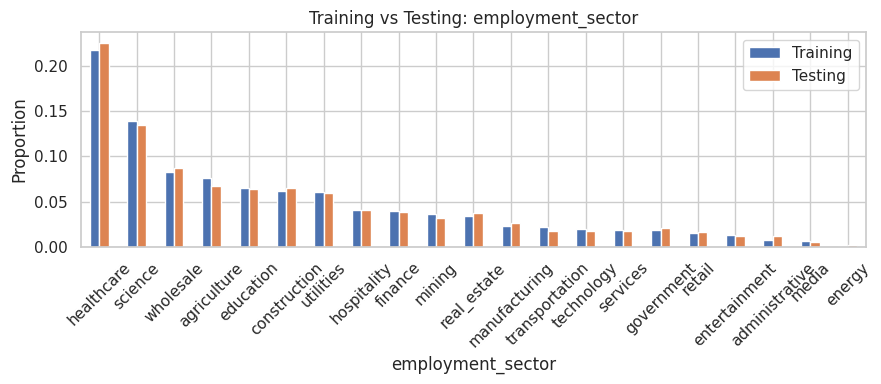

In [ ]:
# ==========================================
# STEP 11: TRAIN VS TEST DISTRIBUTION
# ==========================================

for feature in categorical_features:

    train_distribution = (
        train[feature].value_counts(normalize=True)
    )

    test_distribution = (
        test[feature].value_counts(normalize=True)
    )

    comparison = pd.concat(
        [
            train_distribution.rename("Training"),
            test_distribution.rename("Testing")
        ],
        axis=1
    ).fillna(0)

    comparison.plot(
        kind="bar",
        figsize=(9, 4)
    )

    plt.title(f"Training vs Testing: {feature}")
    plt.ylabel("Proportion")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [ ]:
# ==========================================
# STEP 12: SEPARATE FEATURES AND TARGET
# ==========================================

X = train.drop(
    columns=["covid_vaccine", "respondent_id"]
)

y = train["covid_vaccine"]

X_test = test.drop(
    columns=["respondent_id"]
)

test_ids = test["respondent_id"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_test shape:", X_test.shape)

X shape: (4756, 29)
y shape: (4756,)
X_test shape: (4749, 29)


In [ ]:
# ==========================================
# STEP 14: PREPROCESSING PIPELINE
# ==========================================

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [ ]:
# ==========================================
# STEP 15: TRAIN VALIDATION SPLIT
# ==========================================

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

Training samples: 3804
Validation samples: 952


In [ ]:
# ==========================================
# STEP 16: DEFINE MODELS
# ==========================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

print("Models defined successfully!")

Models defined successfully!


In [ ]:
# ==========================================
# STEP 17: MODEL TRAINING
# ==========================================

results = []

trained_models = {}

for name, model in models.items():

    # Combine preprocessing and model
    pipeline = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            ("model", model)
        ]
    )

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    predictions = pipeline.predict(X_val)

    # Probability predictions
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Evaluation
    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_val, predictions
        ),

        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),

        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            y_val, probabilities
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        )
    })

    trained_models[name] = pipeline

# Results table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC AUC",
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Balanced Accuracy
0,Logistic Regression,0.769958,0.623656,0.745981,0.679356,0.830400,0.763786
2,Random Forest,0.780462,0.733945,0.514469,0.604915,0.819251,0.711993
3,Extra Trees,0.769958,0.716981,0.488746,0.581262,0.812236,0.697571
1,Decision Tree,0.663866,0.486239,0.511254,0.498433,0.624582,0.624582


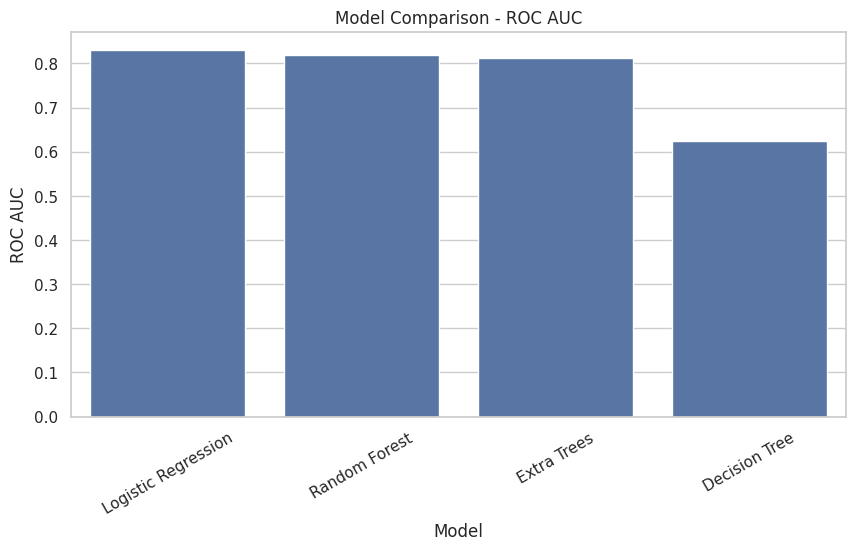

In [ ]:
# ==========================================
# STEP 18: MODEL COMPARISON
# ==========================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="ROC AUC"
)

plt.title("Model Comparison - ROC AUC")
plt.xticks(rotation=30)

plt.show()

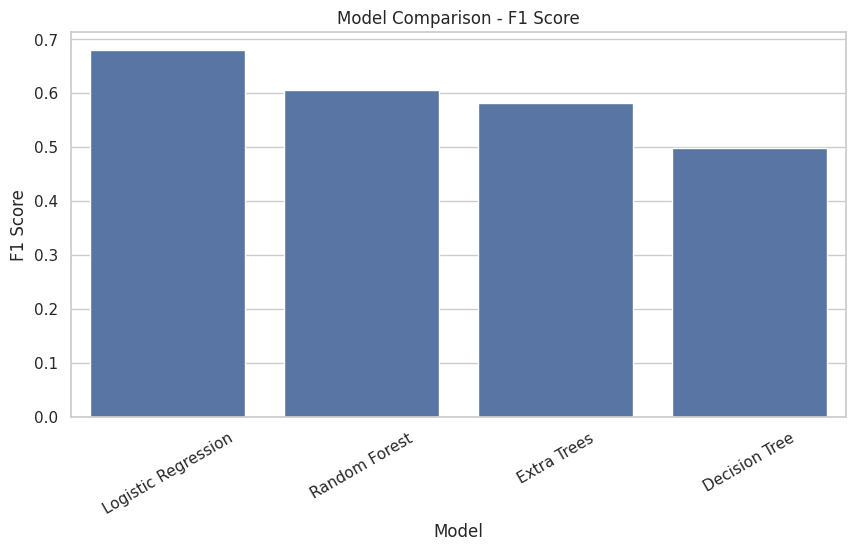

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("Model Comparison - F1 Score")
plt.xticks(rotation=30)

plt.show()

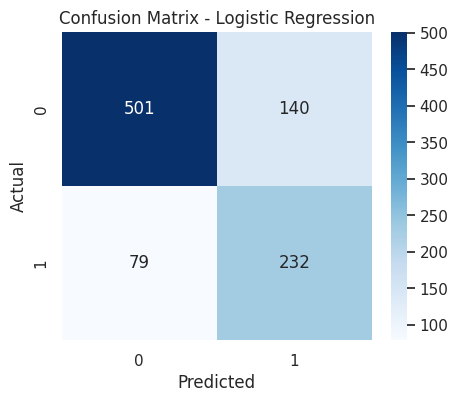

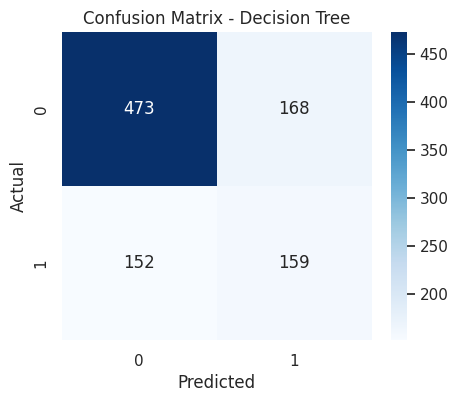

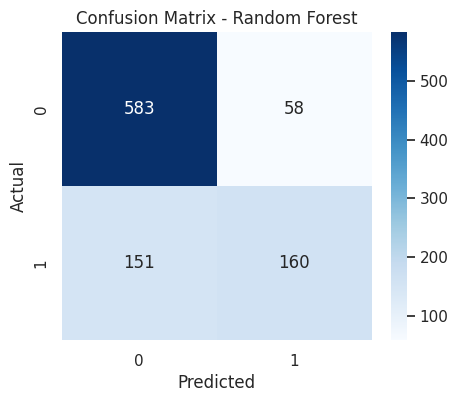

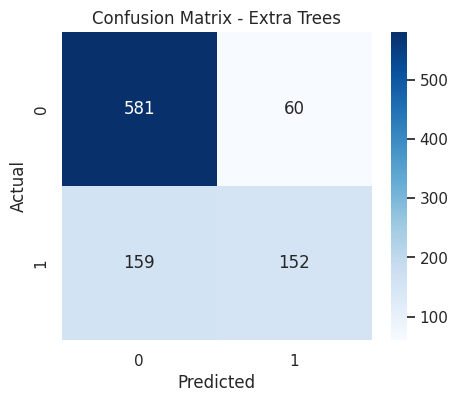

In [ ]:
# ==========================================
# STEP 19: CONFUSION MATRICES
# ==========================================

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_val)

    cm = confusion_matrix(
        y_val,
        predictions
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

In [ ]:
# ==========================================
# STEP 20: STRATIFIED CROSS VALIDATION
# ==========================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "balanced_accuracy": "balanced_accuracy"
}

cv_results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,

        "Mean ROC AUC": scores["test_roc_auc"].mean(),
        "Std ROC AUC": scores["test_roc_auc"].std(),

        "Mean F1": scores["test_f1"].mean(),
        "Std F1": scores["test_f1"].std(),

        "Mean Accuracy": scores["test_accuracy"].mean()
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values(
        by="Mean ROC AUC",
        ascending=False
    )
)

,Model,Mean ROC AUC,Std ROC AUC,Mean F1,Std F1,Mean Accuracy
0,Logistic Regression,0.831293,0.008399,0.671642,0.013833,0.766611
2,Random Forest,0.825904,0.010349,0.615884,0.013266,0.785115
3,Extra Trees,0.813562,0.011614,0.601250,0.013184,0.777757
1,Decision Tree,0.643321,0.020510,0.521738,0.027223,0.682513


In [ ]:
# ==========================================
# STEP 21: RANDOM FOREST TUNING
# ==========================================

rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),

        (
            "model",
            RandomForestClassifier(
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

param_grid = {
    "model__n_estimators": [200, 300, 500, 700],

    "model__max_depth": [None, 5, 10, 15, 20],

    "model__min_samples_split": [2, 5, 10],

    "model__min_samples_leaf": [1, 2, 4],

    "model__max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(random_search.best_score_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 15}

Best cross-validation ROC-AUC:
0.832969795302579


In [ ]:
# ==========================================
# STEP 25: THRESHOLD ANALYSIS
# ==========================================

# Check if random_search has been fitted in the current session; if not, fit it
if not hasattr(random_search, 'best_params_'):
    print("Fitting RandomizedSearchCV in current session memory...")
    random_search.fit(X_train, y_train)

# Retrieve the best estimator
best_rf = random_search.best_estimator_

# Generate probability predictions for the validation subset
rf_probabilities = best_rf.predict_proba(X_val)[:, 1]

# Perform Threshold Analysis
thresholds = np.arange(0.1, 0.91, 0.05)
threshold_results = []

for threshold in thresholds:
    predictions = (rf_probabilities >= threshold).astype(int)
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.340336,0.330843,0.996785,0.496795
1,0.15,0.397059,0.351076,0.996785,0.519263
2,0.20,0.491597,0.388960,0.974277,0.555963
3,0.25,0.580882,0.433934,0.929260,0.591607
4,0.30,0.650210,0.480903,0.890675,0.624577
5,0.35,0.696429,0.521569,0.855305,0.647990
6,0.40,0.727941,0.560185,0.778135,0.651413
7,0.45,0.777311,0.639437,0.729904,0.681682
8,0.50,0.788866,0.678571,0.672026,0.675283
9,0.55,0.788866,0.711538,0.594855,0.647986


In [ ]:
# ==========================================
# STEP 26: FINAL CANDIDATE MODELS
# ==========================================

final_models = {

    "01_Logistic_Regression":
        trained_models["Logistic Regression"],

    "02_Decision_Tree":
        trained_models["Decision Tree"],

    "03_Random_Forest":
        trained_models["Random Forest"],

    "04_Tuned_Random_Forest":
        best_rf,

    "05_Extra_Trees":
        trained_models["Extra Trees"]
}

print("Number of candidate models:", len(final_models))

Number of candidate models: 5


In [ ]:
# ==========================================
# STEP 27: TRAIN FINAL MODELS
# ==========================================

for name, model in final_models.items():

    model.fit(X, y)

    print(name, "trained successfully")

01_Logistic_Regression trained successfully
02_Decision_Tree trained successfully
03_Random_Forest trained successfully
04_Tuned_Random_Forest trained successfully
05_Extra_Trees trained successfully


In [ ]:
# ==========================================
# STEP 28: GENERATE TEST PREDICTIONS
# ==========================================

test_predictions = {}

for name, model in final_models.items():

    predictions = model.predict(X_test)

    test_predictions[name] = predictions

    print(name)
    print("Predictions generated:", len(predictions))

01_Logistic_Regression
Predictions generated: 4749
02_Decision_Tree
Predictions generated: 4749
03_Random_Forest
Predictions generated: 4749
04_Tuned_Random_Forest
Predictions generated: 4749
05_Extra_Trees
Predictions generated: 4749


In [ ]:
# ==========================================
# STEP 29: SAVE PREDICTIONS
# ==========================================

for name, predictions in test_predictions.items():

    submission = pd.DataFrame({

        "respondent_id": test_ids,

        "covid_vaccine": predictions

    })

    filename = f"{name}.csv"

    submission.to_csv(
        filename,
        index=False
    )

    print("Saved:", filename)

Saved: 01_Logistic_Regression.csv
Saved: 02_Decision_Tree.csv
Saved: 03_Random_Forest.csv
Saved: 04_Tuned_Random_Forest.csv
Saved: 05_Extra_Trees.csv


In [92]:
from google.colab import files
import os

# List of generated prediction files
prediction_files = [
    "01_Logistic_Regression.csv",
    "02_Decision_Tree.csv",
    "03_Random_Forest.csv",
    "04_Tuned_Random_Forest.csv",
    "05_Extra_Trees.csv"
]

# Download the tuned random forest model's predictions by default (often the best performer)
best_model_file = "04_Tuned_Random_Forest.csv"

if os.path.exists(best_model_file):
    print(f"Downloading {best_model_file}...")
    files.download(best_model_file)
else:
    print(f"File {best_model_file} not found. Please verify you have run step 29.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==========================================
# STEP 31: SAVE MODEL RESULTS
# ==========================================

results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

cv_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
